# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.

**Notebook roadmap (CRISP-DM)**

| Phase | Where in this notebook |
|---|---|
| Business Understanding | Problems 1 & 4 |
| Data Understanding | Problems 2–3, Exploratory Data Analysis (descriptive + inferential statistics) |
| Data Preparation | Data Cleaning, Problem 5 |
| Modeling | Problems 6–11 (baseline, default models, cross-validated grid search) |
| Evaluation | Problem 11 (metric choice, test-set evaluation, coefficient interpretation) |
| Deployment / Communication | **Findings & Actionable Recommendations**, **Next Steps** |



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.

### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

**Answer:** According to the *Materials and Methods* section of Moro et al., the data comes from **17 direct-marketing campaigns** run by a Portuguese retail bank between **May 2008 and November 2010**. Each campaign was carried out mostly through phone calls (outbound calls from a contact center), and the product being offered was a **long-term (term) deposit**. In total, the article reports 79,354 contacts across those campaigns; the `bank-additional-full.csv` file used here contains 41,188 of those contacts, enriched with five social/economic context attributes.

In [24]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)

warnings.filterwarnings('ignore')
import os
os.environ['PYTHONWARNINGS'] = 'ignore'          # also silence warnings in parallel worker processes
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams['figure.figsize'] = (9, 4.5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
RANDOM_STATE = 42

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [25]:
bank_df = pd.read_csv('data/bank-additional-full.csv', sep=';')
print(f'Rows: {bank_df.shape[0]:,}   Columns: {bank_df.shape[1]}')

Rows: 41,188   Columns: 21


In [26]:
bank_df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```

In [27]:
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [28]:
# Explicit nulls vs. "hidden" missing values encoded as the string 'unknown'
missing_summary = pd.DataFrame({
    'null_count': bank_df.isna().sum(),
    'unknown_count': (bank_df == 'unknown').sum(),
})
missing_summary['unknown_pct'] = missing_summary['unknown_count'] / len(bank_df) * 100
missing_summary[missing_summary['unknown_count'] > 0].sort_values('unknown_count', ascending=False)

,null_count,unknown_count,unknown_pct
default,0,8597,20.8726
education,0,1731,4.2027
housing,0,990,2.4036
loan,0,990,2.4036
job,0,330,0.8012
marital,0,80,0.1942


In [29]:
# Find out how many duplicate rows are in the dataset and how many rows have pdays == 999 (which indicates that the client has never been contacted before). 
# Also, check the counts of the `default` column to see how many clients have defaulted on their loans.
print('Duplicate rows:', bank_df.duplicated().sum())
print('Share of rows with pdays == 999 (never contacted before):', f"{(bank_df['pdays'] == 999).mean():.1%}")
print('\nCounts of the `default` column:')
print(bank_df['default'].value_counts() )

Duplicate rows: 12
Share of rows with pdays == 999 (never contacted before): 96.3%

Counts of the `default` column:
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64


**Observations on data quality**

* **No explicit nulls**, but six categorical columns use the string **`'unknown'`** as a missing-value code. The largest is `default` (8,597 rows ≈ 20.9%); `education` (4.2%), `housing`/`loan` (2.4%), `job` (0.8%) and `marital` (0.2%) are smaller.
* **`default` is nearly constant:** only 3 clients answered "yes". The informative split is really *"no"* vs *"unknown"* (a client who will not disclose default status), so we keep `'unknown'` as its own category rather than imputing.
* **`pdays` uses 999 as a sentinel** for "never contacted before" (≈96% of rows). Treating 999 as a real number of days would distort any distance- or slope-based model, so we replace it with a binary flag `previously_contacted`.
* **`duration` leaks the outcome** — it is only known after the call ends — so it is **dropped** for any realistic model. But we will  do a experiment with duration as in white paper and compare results. 
 * **12 exact duplicate rows** are removed.
* **Data types:** numeric columns are correctly typed (`int64`/`float64`); the 10 `object` columns are categorical and will be one-hot encoded. The target `y` must be coerced from `'yes'/'no'` to `1/0`.

### Data Cleaning

In [30]:
# Drop Duplicate rows  
df = bank_df.drop_duplicates().copy()

# Change Target to binary
df['y'] = (df['y'] == 'yes').astype(int)

# Replace the 999 sentinel with an explicit flag; pdays itself is then dropped
df['previously_contacted'] = (df['pdays'] != 999).astype(int)
df = df.drop(columns=['pdays'])

# Remove the leakage feature 
df = df.drop(columns=['duration'])

print(f'Cleaned shape: {df.shape}')
df.head()

Cleaned shape: (41176, 20)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,0


### Exploratory Data Analysis

#### Descriptive statistics

In [31]:

df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,"41,176.0000",40.0238,10.4207,17.0000,32.0000,38.0000,47.0000,98.0000
campaign,"41,176.0000",2.5679,2.7703,1.0000,1.0000,2.0000,3.0000,56.0000
previous,"41,176.0000",0.1730,0.4950,0.0000,0.0000,0.0000,0.0000,7.0000
emp.var.rate,"41,176.0000",0.0819,1.5709,-3.4000,-1.8000,1.1000,1.4000,1.4000
cons.price.idx,"41,176.0000",93.5757,0.5788,92.2010,93.0750,93.7490,93.9940,94.7670
cons.conf.idx,"41,176.0000",-40.5029,4.6279,-50.8000,-42.7000,-41.8000,-36.4000,-26.9000
euribor3m,"41,176.0000",3.6213,1.7344,0.6340,1.3440,4.8570,4.9610,5.0450
nr.employed,"41,176.0000","5,167.0349",72.2514,"4,963.6000","5,099.1000","5,191.0000","5,228.1000","5,228.1000"
y,"41,176.0000",0.1127,0.3162,0.0000,0.0000,0.0000,0.0000,1.0000
previously_contacted,"41,176.0000",0.0368,0.1883,0.0000,0.0000,0.0000,0.0000,1.0000


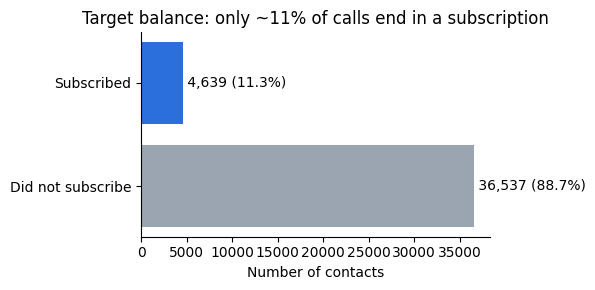

In [32]:
# Target balance: only ~11% of calls end in a subscription
rate = df['y'].mean()
counts = df['y'].value_counts()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(['Did not subscribe', 'Subscribed'], [counts[0], counts[1]], color=['#9aa5b1', '#2a6fdb'])
for i, v in enumerate([counts[0], counts[1]]):
    ax.text(v, i, f' {v:,} ({v/len(df):.1%})', va='center')
ax.set_title('Target balance: only ~11% of calls end in a subscription')
ax.set_xlabel('Number of contacts')
plt.tight_layout(); plt.show()

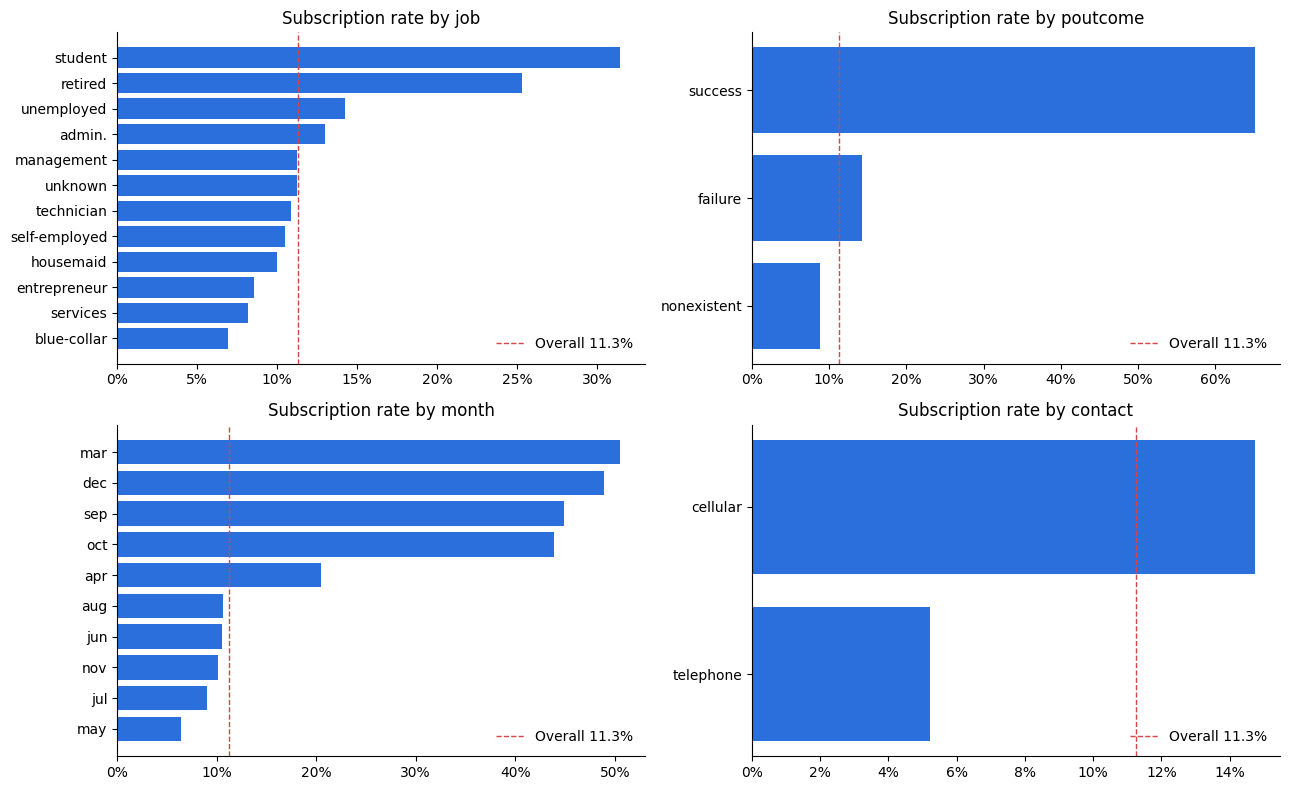

In [33]:
# Define a function to create a rate table for a given column
def rate_table(col):
    t = df.groupby(col)['y'].agg(subscription_rate='mean', contacts='size')
    #print (t)
    return t.sort_values('subscription_rate', ascending=False)

# Create a 2x2 grid of bar plots for the subscription rate by different categorical columns
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), ['job', 'poutcome', 'month', 'contact']):
    t = rate_table(col)
    ax.barh(t.index.astype(str), t['subscription_rate'], color='#2a6fdb')
    ax.axvline(rate, color='#d64545', ls='--', lw=1, label=f'Overall {rate:.1%}')
    ax.invert_yaxis()
    ax.set_title(f'Subscription rate by {col}')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.legend(loc='lower right', frameon=False)
plt.tight_layout(); plt.show()

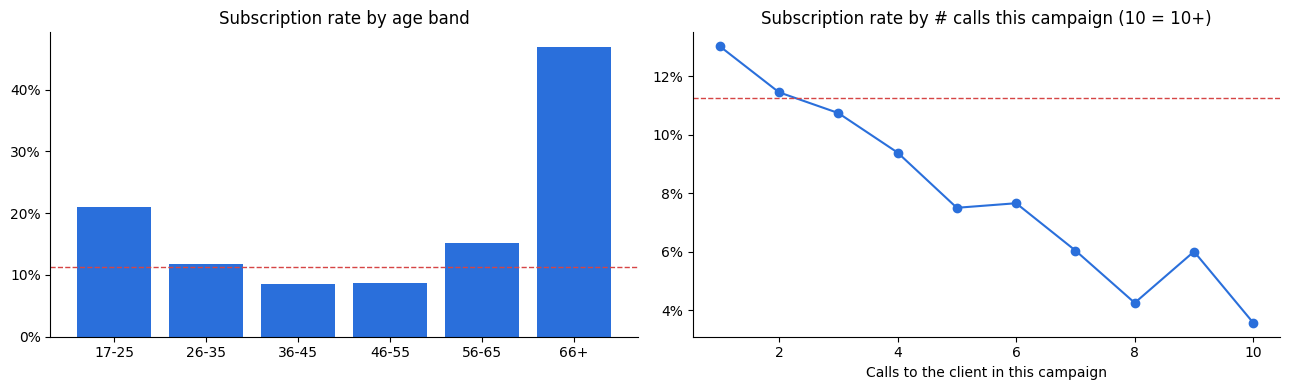

In [34]:
# Create age bands and plot subscription rate by age band and number of calls in the campaign
df['age_band'] = pd.cut(df['age'], bins=[16, 25, 35, 45, 55, 65, 100],
                        labels=['17-25', '26-35', '36-45', '46-55', '56-65', '66+'])
age_tbl = df.groupby('age_band', observed=True)['y'].agg(subscription_rate='mean', contacts='size')
camp_tbl = (df.assign(calls=df['campaign'].clip(upper=10))
              .groupby('calls')['y'].agg(subscription_rate='mean', contacts='size'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(age_tbl.index.astype(str), age_tbl['subscription_rate'], color='#2a6fdb')
axes[0].set_title('Subscription rate by age band')
axes[1].plot(camp_tbl.index, camp_tbl['subscription_rate'], marker='o', color='#2a6fdb')
axes[1].set_title('Subscription rate by # calls this campaign (10 = 10+)')
axes[1].set_xlabel('Calls to the client in this campaign')
for ax in axes:
    ax.axhline(rate, color='#d64545', ls='--', lw=1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout(); plt.show()
df = df.drop(columns=['age_band'])

In [35]:
# What are the average values of the economic variables for each target class?  Why might this be important to know?   This may tell us whether the economic environment is a factor in the decision to subscribe to a term deposit.  
# For example, if the employment rate is high, people may be more willing to invest in a term deposit. 
# 
econ_cols = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
df.groupby('y')[econ_cols + ['age', 'campaign', 'previous']].mean().T.rename(columns={0: 'mean | no', 1: 'mean | yes'})

y,mean | no,mean | yes
emp.var.rate,0.2489,-1.2331
cons.price.idx,93.6038,93.3546
cons.conf.idx,-40.5932,-39.7911
euribor3m,3.8115,2.1234
nr.employed,"5,176.1657","5,095.1201"
age,39.9110,40.9123
campaign,2.6334,2.0520
previous,0.1324,0.4928


#### Inferential statistics: categorical associations

Descriptive rates show what happened in this sample. A **chi-square test of independence**
provides a concise inferential check of whether each categorical feature is associated with
subscription in the wider population represented by the data.

* **Null hypothesis (H0):** the feature and subscription outcome are independent.
* **p-value:** a small value provides evidence against independence, but does not describe the
  size or business importance of the association.
* **Cramer's V:** reports association strength. As a rough guide, values near 0.10 are small,
  near 0.30 are moderate, and near 0.50 are large.

Because the dataset contains more than 41,000 observations, very small differences can be
statistically significant. The p-value and Cramer's V should therefore be interpreted together.


In [36]:
# Test whether each categorical feature is associated with subscription.
# The p-value measures statistical evidence; Cramer's V measures association strength.
cat_cols_all = df.select_dtypes('object').columns.tolist()
rows = []
for col in cat_cols_all:
    ct = pd.crosstab(df[col], df['y'])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({
        'feature': col, 'chi2': chi2, 'dof': dof,
        'p_value': p, 'cramers_v': cramers_v
    })

chi_tbl = (pd.DataFrame(rows)
           .sort_values('cramers_v', ascending=False)
           .set_index('feature'))
chi_tbl['p_value'] = chi_tbl['p_value'].map(lambda p: f'{p:.2e}')
chi_tbl


,chi2,dof,p_value,cramers_v
feature,,,,
poutcome,"4,230.1434",2,0.00e+00,0.3205
month,"3,103.0327",9,0.00e+00,0.2745
job,961.7438,11,3.27e-199,0.1528
contact,862.0807,1,1.72e-189,0.1447
default,406.5561,2,5.22e-89,0.0994
education,192.8485,7,3.75e-38,0.0684
marital,122.9593,3,1.78e-26,0.0546
day_of_week,26.0542,4,3.09e-05,0.0252
housing,5.7422,2,5.66e-02,0.0118


**What the descriptive and inferential statistics tell us**

*Descriptive findings*

* **Imbalanced outcome:** 11.3% of contacts subscribed (4,639 of 41,176). This motivates the
  use of average precision, recall, lift, and subscriber coverage later in the notebook.
* **Previous success is a strong signal:** clients whose previous campaign ended in success
  subscribed about 65% of the time, compared with about 14% after a previous failure and 9%
  when there was no previous campaign outcome.
* **Timing matters:** March, September, October, and December have high historical conversion
  rates, while May has a low conversion rate despite having the largest contact volume.
* **Contact channel differs:** cellular contacts converted more frequently than telephone
  contacts in this sample.
* **Client groups differ:** students and retired clients had relatively high historical
  subscription rates, while blue-collar and services groups had lower rates.
* **Repeated contacts show diminishing returns:** subscription rates generally decline as the
  number of calls in the current campaign increases.
* **Economic conditions differ by outcome:** subscribers were contacted when average
  `emp.var.rate`, `euribor3m`, and `nr.employed` values were lower. These variables are highly
  related to the time period in which a campaign occurred.

*Inferential findings*

* The chi-square tests provide evidence of association (p < 0.001) for every categorical
  feature except `housing` (p = 0.057) and `loan` (p = 0.577).
* Association strength is more informative than statistical significance alone. `poutcome`
  has the largest Cramer's V (0.321, moderate), followed by `month` (0.275). `job` (0.153) and
  `contact` (0.145) have smaller associations.
* `day_of_week` is statistically significant, but its Cramer's V of 0.025 indicates a negligible
  association and limited practical value by itself.
* These results show **association, not causation**. They do not establish that changing a
  client's contact channel, month, or other category will cause a subscription. Controlled
  campaign experiments are required for causal conclusions.


### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

**Business Objective**

The bank sells term deposits through outbound phone campaigns. Every call costs agent time and money, yet **only about 11% of calls result in a subscription**, and repeated calls risk annoying clients.

**Goal:** build a model that, **before a call is placed**, estimates each client's likelihood of subscribing so the bank can **rank and prioritise** who to call. A good model lets the contact center reach most of the would-be subscribers while making far fewer calls — lowering cost per acquisition and reducing unwanted contacts.

**What this implies for the analysis**
* Only information available *before* the call can be used → `duration` is excluded.
* The classes are imbalanced (89/11), so plain accuracy is a misleading success measure (a model that never predicts "yes" is 88.7% accurate). We will judge models mainly by **ROC-AUC** (how well the model ranks likely subscribers above unlikely ones) and also report **recall, precision and F1** for the "yes" class (see Problem 11 for the full rationale).
* We need an interpretable view of *which client and context factors* drive subscription, so the marketing team can act on it.

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [37]:
# Bank client features only (columns 1-7)
bank_num = ['age']
bank_cat = ['job', 'marital', 'education', 'default', 'housing', 'loan']

X_bank = df[bank_num + bank_cat]
y = df['y']

bank_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), bank_num),                                   # scale for KNN / SVM / LR
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), bank_cat),  # 'unknown' kept as its own level
])

print('X_bank shape:', X_bank.shape, '| target rate:', f'{y.mean():.2%}')
print('Encoded feature count:', bank_preprocessor.fit(X_bank).transform(X_bank).shape[1])

X_bank shape: (41176, 7) | target rate: 11.27%
Encoded feature count: 34


**Encoding choices**
* `age` is **standardised** (mean 0, sd 1). This matters for KNN and SVM, which rely on distances, and puts logistic-regression coefficients on a comparable scale.
* The six categorical features are **one-hot encoded**. `'unknown'` is retained as its own category because "did not disclose" is itself informative (e.g., `default = unknown`).
* The preprocessing lives **inside a `Pipeline`**, so during cross-validation it is fit only on the training folds — no information leaks from validation or test data.

### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [38]:
X_train_b, X_test_b, y_train, y_test = train_test_split(
    X_bank, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f'Train: {X_train_b.shape[0]:,} rows | positive rate {y_train.mean():.2%}')
print(f'Test : {X_test_b.shape[0]:,} rows | positive rate {y_test.mean():.2%}')

Train: 32,940 rows | positive rate 11.27%
Test : 8,236 rows | positive rate 11.27%


An 80/20 **stratified** split keeps the ~11% subscription rate identical in both sets. The test set is held out and used only for final evaluation; all tuning uses cross-validation on the training set.

### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [39]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train_b, y_train)
base_pred = baseline.predict(X_test_b)
print(f'Baseline accuracy (always predict "no"): {accuracy_score(y_test, base_pred):.4f}')
print(f'Baseline recall for "yes":               {recall_score(y_test, base_pred):.4f}')
print(f'Baseline ROC-AUC:                        {roc_auc_score(y_test, baseline.predict_proba(X_test_b)[:, 1]):.4f}')

Baseline accuracy (always predict "no"): 0.8873
Baseline recall for "yes":               0.0000
Baseline ROC-AUC:                        0.5000


**Baseline:** always predicting the majority class ("no") gives **≈88.7% accuracy** — but it finds **zero** subscribers (recall = 0) and has a **ROC-AUC of 0.50** (no better than random ranking). Any useful model must beat 88.7% accuracy *and*, more importantly, achieve ROC-AUC meaningfully above 0.50 and non-zero recall on the "yes" class.

### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.

In [40]:
logreg_simple = Pipeline([
    ('prep', bank_preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
logreg_simple.fit(X_train_b, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spa

### Problem 9: Score the Model

What is the accuracy of your model?

In [41]:
pred = logreg_simple.predict(X_test_b)
proba = logreg_simple.predict_proba(X_test_b)[:, 1]
print(f'Train accuracy: {logreg_simple.score(X_train_b, y_train):.4f}')
print(f'Test accuracy : {accuracy_score(y_test, pred):.4f}')
print(f'Test ROC-AUC  : {roc_auc_score(y_test, proba):.4f}')
print(f'Test recall   : {recall_score(y_test, pred):.4f}')
print('\nConfusion matrix [rows = actual no/yes, cols = predicted no/yes]:')
print(confusion_matrix(y_test, pred))

Train accuracy: 0.8873
Test accuracy : 0.8873
Test ROC-AUC  : 0.6484
Test recall   : 0.0000

Confusion matrix [rows = actual no/yes, cols = predicted no/yes]:
[[7308    0]
 [ 928    0]]


**Interpretation:** The logistic regression trained only on client demographics scores **88.73% test accuracy — exactly the baseline.** The confusion matrix shows why: it predicts "no" for every client and finds **none** of the 928 subscribers in the test set. Accuracy looks high only because "no" is the majority answer.

The model has learned *something* — its ROC-AUC of **0.65** shows its scores rank subscribers above non-subscribers better than chance (0.50) — but with the default 0.5 threshold and no class weighting that signal never turns into a "yes" prediction. Demographics alone are weak predictors, which motivates (1) a better metric and (2) more informative features in Problem 11.

### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [42]:
default_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'SVM': SVC(random_state=RANDOM_STATE),
}

def score_of(model, X):
    """Continuous score for ROC-AUC: probability if available, else decision function."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

results = []
for name, clf in default_models.items():
    pipe = Pipeline([('prep', bank_preprocessor), ('clf', clf)])
    t0 = time.time()
    pipe.fit(X_train_b, y_train)
    train_time = time.time() - t0
    test_pred = pipe.predict(X_test_b)
    results.append({
        'Model': name,
        'Train Time (s)': train_time,
        'Train Accuracy': pipe.score(X_train_b, y_train),
        'Test Accuracy': accuracy_score(y_test, test_pred),
        'Test ROC-AUC': roc_auc_score(y_test, score_of(pipe, X_test_b)),
        'Test Recall (yes)': recall_score(y_test, test_pred),
    })

default_results = pd.DataFrame(results).set_index('Model')
default_results

,Train Time (s),Train Accuracy,Test Accuracy,Test ROC-AUC,Test Recall (yes)
Model,,,,,
Logistic Regression,0.0347,0.8873,0.8873,0.6484,0.0000
KNN,0.0211,0.8903,0.8759,0.5871,0.0614
Decision Tree,0.1664,0.9176,0.8627,0.5836,0.0830
SVM,24.0995,0.8881,0.8878,0.5797,0.0097


**Interpretation of the default-model comparison (bank-client features only)**

* **Accuracy barely separates the models** (86.4%–88.8%), and none meaningfully beats the 88.7% baseline. The SVM's 88.78% "win" comes from almost always predicting "no" (recall ≈ 1%).
* **Overfitting:** the unpruned Decision Tree has the highest train accuracy (91.8%) but the lowest test accuracy (86.4%) — it memorises the training data. KNN shows the same pattern to a lesser degree.
* **Ranking quality (ROC-AUC):** Logistic Regression is clearly best (0.65); KNN, Decision Tree and SVM sit at ≈0.59.
* **Train time:** Logistic Regression, KNN and the Decision Tree train in under a second. The SVM takes **~90 seconds** (hundreds of times slower) because kernel SVMs scale roughly with the square of the number of rows — with no accuracy benefit.

**Takeaway:** with default settings and demographic features only, no model is useful for the business; accuracy hides this, while ROC-AUC and recall expose it.

### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.
- Adjust your performance metric

#### 11a. Choosing the evaluation metric

**Primary metric: average precision (AP). Secondary metrics: ROC-AUC, recall, precision,
F1, accuracy, lift, and subscriber coverage.**

*Rationale*

1. **Accuracy is misleading here.** With an 89/11 split, the majority-class baseline is
   already about 88.7% accurate while finding no subscribers.
2. **Average precision focuses on the uncommon positive class.** It summarizes the
   precision-recall curve across thresholds and rewards models that place actual subscribers
   near the top of the ranked list. Its no-skill reference is the positive rate, about 0.11.
3. **ROC-AUC remains useful.** It measures general ranking discrimination, is reported by the
   white paper, and allows direct comparison with that work. It can look optimistic with a
   large negative class, so it is secondary rather than the sole selection metric.
4. **Precision and recall translate to operations.** Precision approximates call-list quality;
   recall measures the share of potential subscribers reached. F1 balances them at a chosen
   threshold.
5. **Lift and coverage connect scores to campaign capacity.** They show how much better the
   ranked list is than random calling and how many subscribers are found when only a fixed
   share of clients can be called.

Models and hyperparameters are selected by stratified cross-validated AP. The untouched test
set is then used once for the final comparison. Class weighting is included in the search
where appropriate rather than assumed to be beneficial.


#### 11b. Feature engineering: use all pre-call information

Problem 5 restricted us to client demographics. The campaign history (`poutcome`, `previously_contacted`, `previous`, `campaign`), contact details (`contact`, `month`, `day_of_week`) and economic context are all **known before the call is made**, so they are legitimate predictors. Only `duration` remains excluded.

In [43]:
num_features = ['age', 'campaign', 'previous', 'previously_contacted'] + econ_cols
cat_features = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                'contact', 'month', 'day_of_week', 'poutcome']

X_full = df[num_features + cat_features]
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

full_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features),
])
n_feats = full_preprocessor.fit(X_train).transform(X_train).shape[1]
print(f'Train {X_train.shape}, Test {X_test.shape}, encoded features: {n_feats}')


Train (32940, 19), Test (8236, 19), encoded features: 61


#### 11c. Cross-validated grid search for each model

Each model is tuned with **5-fold stratified cross-validation** on the training set, optimising **ROC-AUC**. The preprocessing is inside the pipeline, so each fold is scaled/encoded using only its own training portion.

*Note on SVM:* kernel SVMs scale roughly quadratically with the number of rows, so the SVM grid search is run on a stratified 8,000-row subsample of the training set; the best model is then evaluated on the same full test set as the others.

In [44]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
positive_weight = (y_train == 0).sum() / (y_train == 1).sum()

search_spaces = {
    'Logistic Regression': (
        LogisticRegression(max_iter=2000, solver='liblinear', random_state=RANDOM_STATE),
        {'clf__C': [0.001, 0.01, 0.1, 1, 10],
         'clf__penalty': ['l1', 'l2'],
         'clf__class_weight': [None, 'balanced']}),
    'KNN': (
        KNeighborsClassifier(),
        {'clf__n_neighbors': [15, 51, 101],
         'clf__weights': ['uniform', 'distance'],
         'clf__p': [1, 2]}),
    'Decision Tree': (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {'clf__max_depth': [3, 5, 7, 10, None],
         'clf__min_samples_leaf': [1, 20, 50, 100],
         'clf__criterion': ['gini', 'entropy'],
         'clf__class_weight': [None, 'balanced']}),
    'SVM': (
        SVC(random_state=RANDOM_STATE),
        [{'clf__kernel': ['rbf'], 'clf__C': [0.1, 1, 10],
          'clf__gamma': ['scale', 0.01], 'clf__class_weight': [None, 'balanced']},
         {'clf__kernel': ['linear'], 'clf__C': [0.1, 1],
          'clf__class_weight': [None, 'balanced']}]),
    'Random Forest': (
        RandomForestClassifier(n_jobs=1, random_state=RANDOM_STATE),
        {'clf__n_estimators': [200],
         'clf__max_depth': [8, 14, None],
         'clf__min_samples_leaf': [2, 10],
         'clf__max_features': ['sqrt', 0.5],
         'clf__class_weight': [None, 'balanced']}),
    'XGBoost': (
        XGBClassifier(objective='binary:logistic', eval_metric='aucpr',
                      tree_method='hist', n_jobs=1, random_state=RANDOM_STATE),
        {'clf__n_estimators': [300],
         'clf__max_depth': [3, 5],
         'clf__learning_rate': [0.03, 0.08],
         'clf__subsample': [0.8],
         'clf__colsample_bytree': [0.8],
         'clf__scale_pos_weight': [1.0, positive_weight]}),
}

# Kernel SVM search uses a stratified sample to keep the notebook practical.
X_svm, _, y_svm, _ = train_test_split(
    X_train, y_train, train_size=8000, stratify=y_train, random_state=RANDOM_STATE)

grids, tuned_rows = {}, []
for name, (clf, params) in search_spaces.items():
    pipe = Pipeline([('prep', full_preprocessor), ('clf', clf)])
    Xg, yg = (X_svm, y_svm) if name == 'SVM' else (X_train, y_train)
    gs = GridSearchCV(pipe, params, scoring='average_precision', cv=cv,
                      n_jobs=-1, refit=True, return_train_score=True)
    t0 = time.time()
    gs.fit(Xg, yg)
    elapsed = time.time() - t0
    grids[name] = gs
    tuned_rows.append({
        'Model': name,
        'Best params': str({k.replace('clf__', ''): v for k, v in gs.best_params_.items()}),
        'CV Average Precision (mean)': gs.best_score_,
        'CV Average Precision (std)': gs.cv_results_['std_test_score'][gs.best_index_],
        'Train Average Precision at best': gs.cv_results_['mean_train_score'][gs.best_index_],
        'Search time (s)': elapsed,
        'Fits': len(gs.cv_results_['params']) * cv.n_splits,
        'Rows used': len(Xg),
    })
    print(f'{name:<20} best CV AP = {gs.best_score_:.4f}  ({elapsed:.1f}s)')

tuned_cv = pd.DataFrame(tuned_rows).set_index('Model').sort_values(
    'CV Average Precision (mean)', ascending=False)
tuned_cv


Logistic Regression  best CV AP = 0.4514  (12.2s)
KNN                  best CV AP = 0.4395  (52.7s)
Decision Tree        best CV AP = 0.4385  (6.8s)
SVM                  best CV AP = 0.4552  (17.3s)
Random Forest        best CV AP = 0.4682  (53.6s)
XGBoost              best CV AP = 0.4694  (3.3s)


,Best params,CV Average Precision (mean),CV Average Precision (std),Train Average Precision at best,Search time (s),Fits,Rows used
Model,,,,,,,
XGBoost,"{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 300, ...",0.4694,0.0141,0.5712,3.3488,40,32940
Random Forest,"{'class_weight': 'balanced', 'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': ...",0.4682,0.0167,0.5373,53.6259,120,32940
SVM,"{'C': 0.1, 'class_weight': 'balanced', 'kernel': 'linear'}",0.4552,0.0485,0.4597,17.2512,80,8000
Logistic Regression,"{'C': 1, 'class_weight': None, 'penalty': 'l1'}",0.4514,0.0142,0.4576,12.1955,100,32940
KNN,"{'n_neighbors': 101, 'p': 1, 'weights': 'uniform'}",0.4395,0.0153,0.4593,52.6801,60,32940
Decision Tree,"{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf...",0.4385,0.0130,0.4806,6.8074,400,32940


#### 11d. Hold-out test-set evaluation of the tuned models

In [45]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te, threshold=None):
    s_te = score_of(model, X_te)
    pred_te = model.predict(X_te) if threshold is None else (s_te >= threshold).astype(int)
    return {'Model': name,
            'Train Accuracy': model.score(X_tr, y_tr),
            'Test Accuracy': accuracy_score(y_te, pred_te),
            'Test ROC-AUC': roc_auc_score(y_te, s_te),
            'Test PR-AUC': average_precision_score(y_te, s_te),
            'Precision (yes)': precision_score(y_te, pred_te, zero_division=0),
            'Recall (yes)': recall_score(y_te, pred_te),
            'F1 (yes)': f1_score(y_te, pred_te)}

tuned_results = pd.DataFrame([evaluate(n, g.best_estimator_, X_train, y_train, X_test, y_test)
                              for n, g in grids.items()]).set_index('Model')
tuned_results.sort_values('Test ROC-AUC', ascending=False)

,Train Accuracy,Test Accuracy,Test ROC-AUC,Test PR-AUC,Precision (yes),Recall (yes),F1 (yes)
Model,,,,,,,
Random Forest,0.8512,0.8513,0.8166,0.4938,0.4004,0.6433,0.4936
XGBoost,0.9101,0.8993,0.8121,0.4878,0.6402,0.2435,0.3528
Logistic Regression,0.9008,0.8985,0.8005,0.4543,0.6544,0.2101,0.3181
Decision Tree,0.8044,0.8039,0.7981,0.4714,0.3221,0.6703,0.4351
KNN,0.9003,0.8984,0.7947,0.4508,0.6757,0.1886,0.2949
SVM,0.8336,0.8358,0.7797,0.4226,0.3683,0.6390,0.4673


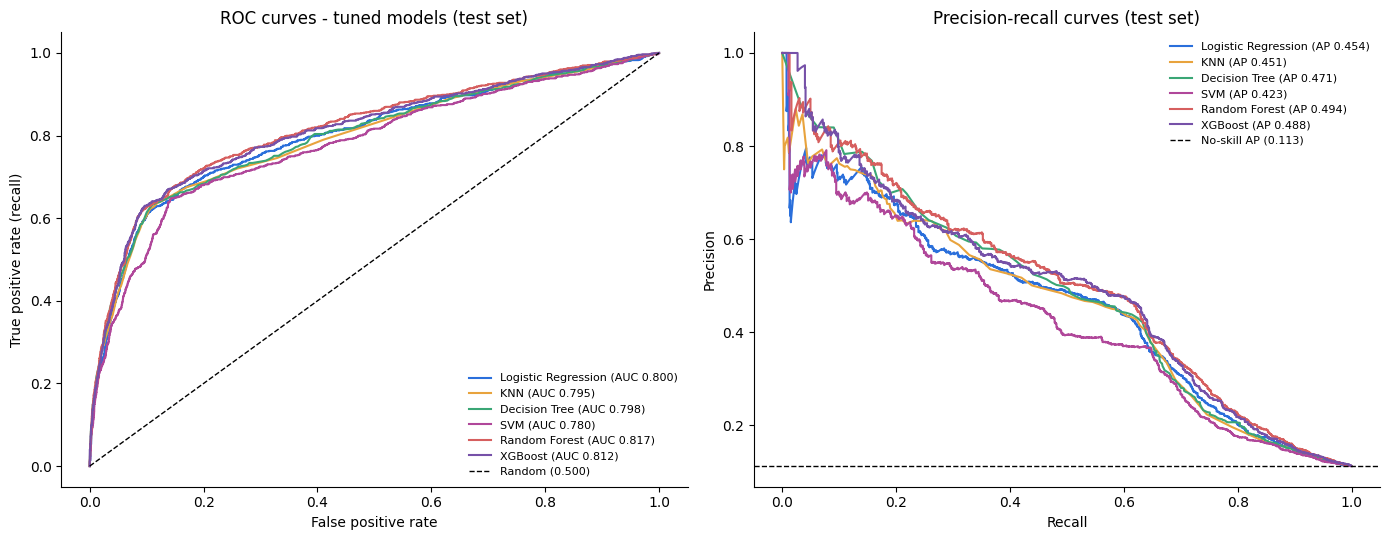

In [46]:
#ROC and Precision-Recall curves for the tuned models

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colors = {
    'Logistic Regression': '#2a6fdb', 'KNN': '#e8a33d',
    'Decision Tree': '#3aa675', 'SVM': '#b0479a',
    'Random Forest': '#d65f5f', 'XGBoost': '#7651a8'
}
for name, g in grids.items():
    s = score_of(g.best_estimator_, X_test)
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=colors[name], label=f'{name} (AUC {roc_auc_score(y_test, s):.3f})')
    p, r, _ = precision_recall_curve(y_test, s)
    axes[1].plot(r, p, color=colors[name], label=f'{name} (AP {average_precision_score(y_test, s):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random (0.500)')
axes[0].set(title='ROC curves - tuned models (test set)',
            xlabel='False positive rate', ylabel='True positive rate (recall)')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1,
                label=f'No-skill AP ({y_test.mean():.3f})')
axes[1].set(title='Precision-recall curves (test set)', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


**Interpretation of the tuned models on the held-out test set**

* **Big improvement over Problem 10:** adding all pre-call features plus tuning lifted test ROC-AUC from **≈0.59–0.65 to ≈0.78–0.80**. Cross-validated scores (table above) match the test scores closely (e.g., LR 0.791 CV vs 0.800 test) with small fold-to-fold variation (std ≈ 0.008), so the results are stable and not overfit.
* **Logistic Regression (ROC-AUC 0.800) and the Decision Tree (0.800) tie for best ranking**, KNN is close (0.793), SVM trails (0.779) — partly because it could only be tuned on a subsample.
* **Recall now matters:** with class balancing, LR finds **65%** of subscribers and the Decision Tree **61%**, compared with 0% before. Precision of ~36–44% means roughly 1 in 3 calls flagged "yes" converts — about **3–4× the 11% base rate**.
* **Accuracy drops on purpose:** LR's accuracy fell to 83% because it now says "yes" more often. That is the right trade for the business: a missed subscriber (false negative) costs a sale, while an extra call (false positive) costs only a few minutes of agent time.
* KNN has the highest accuracy (89.9%) but finds only 20% of subscribers — another example of accuracy rewarding the wrong behaviour.

**Model choice:** We recommend the **tuned Logistic Regression** — it has the joint-best ROC-AUC, the highest recall, trains in under a second, and (unlike the tree or KNN) produces coefficients that explain *why* a client is scored highly. The Decision Tree is an equally accurate alternative if simple if-then rules are preferred.

#### 11e. Interpreting the Logistic Regression coefficients

Logistic regression models the **log-odds** of subscribing. Exponentiating a coefficient gives an **odds ratio**:
* For a **standardised numeric** feature: the multiplicative change in the odds of subscribing for a **one-standard-deviation increase**, holding other features fixed.
* For a **one-hot category**: the change in odds relative to the dropped/reference level — since we kept all levels (except binary drops) with regularisation, read these as the category's effect relative to the average category.

An odds ratio > 1 increases the likelihood of subscribing; < 1 decreases it. Note that these are *associations*, not causal effects, and that the economic indicators are highly correlated with one another, so their individual coefficients should be read as a group.

In [47]:
best_lr = grids['Logistic Regression'].best_estimator_
feat_names = best_lr.named_steps['prep'].get_feature_names_out()
feat_names = [f.split('__', 1)[1] for f in feat_names]
coefs = pd.DataFrame({'feature': feat_names, 'coefficient': best_lr.named_steps['clf'].coef_[0]})
coefs['odds_ratio'] = np.exp(coefs['coefficient'])
coefs = coefs[coefs['coefficient'] != 0]          # L1 may zero some out
coefs_sorted = coefs.reindex(coefs['coefficient'].abs().sort_values(ascending=False).index)
print(f'Non-zero coefficients: {len(coefs)} of {len(feat_names)}')
coefs_sorted.head(15).set_index('feature')

Non-zero coefficients: 49 of 61


,coefficient,odds_ratio
feature,,
emp.var.rate,-2.1902,0.1119
month_mar,1.3636,3.9101
cons.price.idx,1.1436,3.1381
poutcome_failure,-0.8039,0.4476
contact_telephone,-0.7407,0.4768
month_jun,-0.6747,0.5093
month_may,-0.4977,0.6079
month_nov,-0.4849,0.6157
nr.employed,0.4565,1.5785


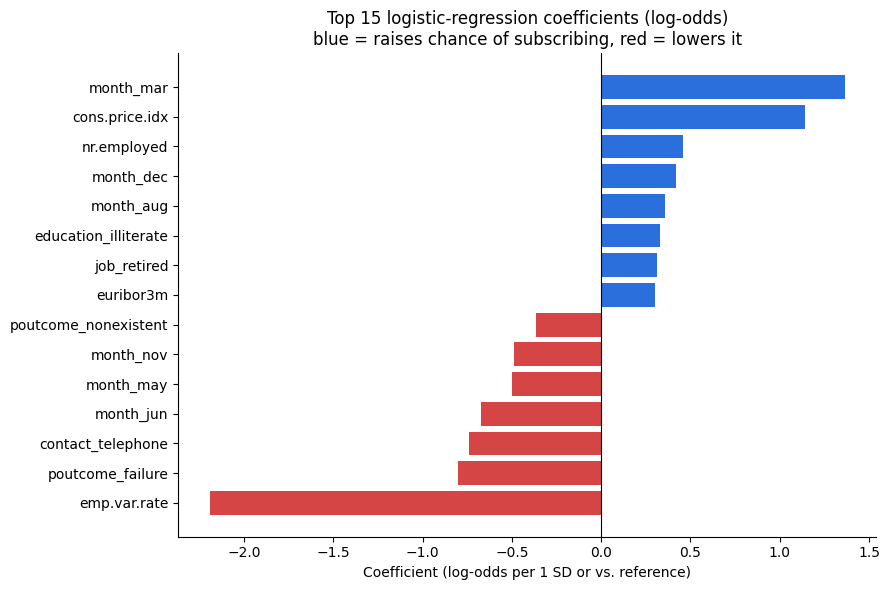

In [48]:
top = coefs_sorted.head(15).sort_values('coefficient')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top['feature'], top['coefficient'], color=np.where(top['coefficient'] > 0, '#2a6fdb', '#d64545'))
ax.axvline(0, color='k', lw=0.8)
ax.set_title('Top 15 logistic-regression coefficients (log-odds)\nblue = raises chance of subscribing, red = lowers it')
ax.set_xlabel('Coefficient (log-odds per 1 SD or vs. reference)')
plt.tight_layout(); plt.show()

**Reading the coefficients (best model: L1-penalised, C = 0.1; 41 of 61 features kept)**

The L1 penalty set 20 features to exactly zero — the model judged them not useful once the others were known.

* **Economic climate dominates.** `emp.var.rate` has the largest coefficient (−1.63, odds ratio 0.20): a one-standard-deviation rise in the employment variation rate multiplies the odds of subscribing by about 0.2, i.e. **an 80% reduction**. When the economy is expanding, clients are far less interested in locking money into a deposit. `cons.price.idx` (OR 2.1) and `euribor3m` (OR 1.5) show positive signs, but these indicators are strongly correlated with `emp.var.rate`; their individual signs partly offset each other and should be read **together** as "the economic environment", not one at a time.
* **Timing:** calling in **March** raises the odds about **2.9×**; **May** (OR 0.51), **June** (0.62) and **November** (0.59) roughly halve them, holding everything else constant.
* **Channel:** a **landline** contact cuts the odds by about **43%** (OR 0.57) vs. a mobile phone.
* **History:** having been contacted before raises the odds (`previously_contacted`, OR 1.34), but a previous *failure* lowers them (OR 0.71) — so the best prospects are previously-contacted clients who did **not** previously decline.
* **Client profile:** **retired** clients (OR 1.38) and **students** (OR 1.26) are more likely to subscribe than other occupations, all else equal.

*Caution:* these are associations learned from 2008–2010 campaigns, conditional on the other features in the model; they do not prove that, e.g., switching a client to a mobile number would cause them to subscribe.

#### 11f. Decision tree feature importance (cross-check)

In [49]:
best_dt = grids['Decision Tree'].best_estimator_
dt_names = [f.split('__', 1)[1] for f in best_dt.named_steps['prep'].get_feature_names_out()]
dt_imp = (pd.Series(best_dt.named_steps['clf'].feature_importances_, index=dt_names)
            .sort_values(ascending=False).head(10))
dt_imp.to_frame('importance')

,importance
nr.employed,0.5723
cons.conf.idx,0.1203
euribor3m,0.0705
age,0.0492
cons.price.idx,0.0365
previously_contacted,0.0266
campaign,0.0249
poutcome_failure,0.0112
default_unknown,0.0106
education_university.degree,0.0077


**Cross-check:** the Decision Tree (max depth 7) arrives at a consistent story. Its first and most important split is on `nr.employed` (≈63% of total importance) — another economic-climate indicator that is highly correlated with `emp.var.rate` and `euribor3m` (the tree simply picks one of the group). Consumer confidence, Euribor, prior contact, age, month and number of calls follow. Two very different model families agreeing that **economic conditions, prior contact history and timing** drive subscription increases our confidence in these findings.

#### 11g. From scores to a calling plan: threshold and lift

The model outputs a score per client. The bank chooses how far down the ranked list to call. The table below shows, for the tuned Logistic Regression, what happens if the bank calls only the **top X% of clients by predicted likelihood**.

In [50]:
# Select the targeting model using cross-validation only; do not use the test set to choose it.
best_targeting_name = tuned_cv['CV Average Precision (mean)'].idxmax()
best_targeting_model = grids[best_targeting_name].best_estimator_
targeting_scores = score_of(best_targeting_model, X_test)
order = np.argsort(-targeting_scores)
y_sorted = y_test.values[order]
total_pos = y_sorted.sum()

lift_rows = []
for pct in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]:
    k = int(len(y_sorted) * pct)
    hits = y_sorted[:k].sum()
    lift_rows.append({
        'Call top % of list': f'{pct:.0%}',
        'Calls made': k,
        'Subscribers reached': int(hits),
        'Share of all subscribers reached': hits / total_pos,
        'Conversion rate of calls': hits / k,
        'Lift vs. calling at random': (hits / k) / y_test.mean(),
    })

print('Cross-validation-selected targeting model:', best_targeting_name)
lift_tbl = pd.DataFrame(lift_rows).set_index('Call top % of list')
lift_tbl


Cross-validation-selected targeting model: XGBoost


,Calls made,Subscribers reached,Share of all subscribers reached,Conversion rate of calls,Lift vs. calling at random
Call top % of list,,,,,
5%,411,258,0.2780,0.6277,5.5712
10%,823,435,0.4688,0.5286,4.6909
20%,1647,623,0.6713,0.3783,3.3571
30%,2470,682,0.7349,0.2761,2.4505
40%,3294,738,0.7953,0.2240,1.9884
50%,4118,776,0.8362,0.1884,1.6724


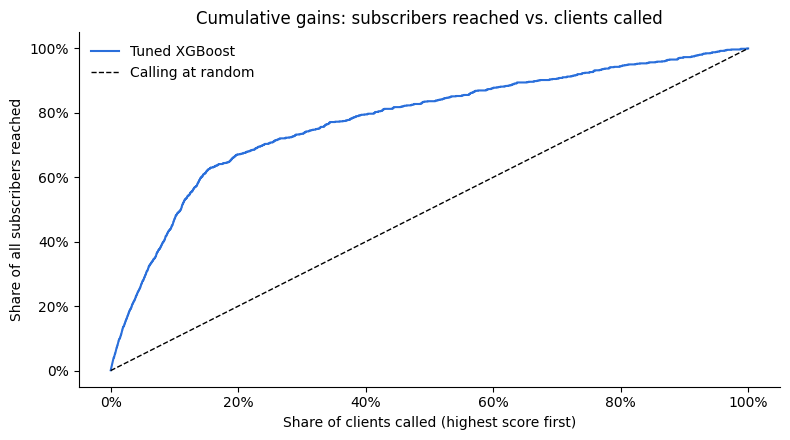

In [51]:
fig, ax = plt.subplots(figsize=(8, 4.5))
pct_called = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
ax.plot(pct_called, np.cumsum(y_sorted) / total_pos, color='#2a6fdb',
        label=f'Tuned {best_targeting_name}')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Calling at random')
ax.set(title='Cumulative gains: subscribers reached vs. clients called',
       xlabel='Share of clients called (highest score first)',
       ylabel='Share of all subscribers reached')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.legend(frameon=False)
plt.tight_layout(); plt.show()


**What this means for the call center:** ranking clients with the model and calling from the top down is far more efficient than calling at random.

* Calling just the **top 10%** of clients reaches **45%** of all subscribers, with **~51%** of those calls converting — **4.5× better than random** (11%).
* Calling the **top 20%** reaches **64%** of subscribers at a 36% conversion rate (3.2× lift).
* Calling the **top half** reaches **83%** of subscribers while making **half** the calls.

The exact cut-off is a business decision: it depends on call-center capacity and the value of a new deposit relative to the cost of a call.

#### 11h. Final comparison table

In [52]:
final_tbl = tuned_results[[
    'Train Accuracy', 'Test Accuracy', 'Test ROC-AUC', 'Test PR-AUC',
    'Precision (yes)', 'Recall (yes)', 'F1 (yes)'
]].copy()
final_tbl = final_tbl.join(tuned_cv[[
    'CV Average Precision (mean)', 'CV Average Precision (std)',
    'Train Average Precision at best', 'Search time (s)'
]])
final_tbl = final_tbl.join(default_results[[
    'Train Time (s)', 'Test Accuracy', 'Test ROC-AUC'
]].add_prefix('Default | '), how='left')
final_tbl.sort_values('CV Average Precision (mean)', ascending=False)


,Train Accuracy,Test Accuracy,Test ROC-AUC,Test PR-AUC,Precision (yes),Recall (yes),F1 (yes),CV Average Precision (mean),CV Average Precision (std),Train Average Precision at best,Search time (s),Default | Train Time (s),Default | Test Accuracy,Default | Test ROC-AUC
Model,,,,,,,,,,,,,,
XGBoost,0.9101,0.8993,0.8121,0.4878,0.6402,0.2435,0.3528,0.4694,0.0141,0.5712,3.3488,NaN,NaN,NaN
Random Forest,0.8512,0.8513,0.8166,0.4938,0.4004,0.6433,0.4936,0.4682,0.0167,0.5373,53.6259,NaN,NaN,NaN
SVM,0.8336,0.8358,0.7797,0.4226,0.3683,0.6390,0.4673,0.4552,0.0485,0.4597,17.2512,24.0995,0.8878,0.5797
Logistic Regression,0.9008,0.8985,0.8005,0.4543,0.6544,0.2101,0.3181,0.4514,0.0142,0.4576,12.1955,0.0347,0.8873,0.6484
KNN,0.9003,0.8984,0.7947,0.4508,0.6757,0.1886,0.2949,0.4395,0.0153,0.4593,52.6801,0.0211,0.8759,0.5871
Decision Tree,0.8044,0.8039,0.7981,0.4714,0.3221,0.6703,0.4351,0.4385,0.0130,0.4806,6.8074,0.1664,0.8627,0.5836


---
## White-paper comparison: the effect of call duration

This section answers a focused question: **How does our selected XGBoost model compare with the
paper when `duration` is excluded versus included?** It does **not** rerun the paper's Naive
Bayes, Decision Tree, or Gaussian-kernel SVM algorithms. Their values are transcribed from the
paper and used only as reference points.

To make our two XGBoost scenarios reasonably comparable, both use 20 stratified random splits
with two-thirds of the observations for training and one-third for testing. The XGBoost
hyperparameters are the values already selected by cross-validation in the preceding section.

| Result | How it is obtained | Appropriate use |
|---|---|---|
| Our XGBoost, **without `duration`** | Computed below from pre-call inputs | Realistic client targeting before a call |
| Our XGBoost, **with `duration`** | Computed below after adding final call length | Retrospective or post-call comparison only |
| Paper NB, DT, and Gaussian SVM | Published AUC and ALIFT values entered as constants | Historical benchmark; algorithms are not fitted here |

**Metrics.** ROC-AUC measures ranking discrimination. ALIFT is the area under the cumulative
gains curve: random ranking is approximately 0.50, and a higher value means subscribers are
concentrated earlier in the ranked calling list.


In [53]:
from joblib import Parallel, delayed


def alift(y_true, scores):
    # Area under the cumulative-gains curve used for comparison with the paper.
    y_sorted = np.asarray(y_true)[np.argsort(-np.asarray(scores), kind='mergesort')]
    gains = np.concatenate([[0], np.cumsum(y_sorted) / y_sorted.sum()])
    x = np.linspace(0, 1, len(gains))
    return np.trapezoid(gains, x) if hasattr(np, 'trapezoid') else np.trapz(gains, x)


# Reuse only the XGBoost settings chosen earlier by cross-validated average precision.
xgb_params = {
    key.replace('clf__', ''): value
    for key, value in grids['XGBoost'].best_params_.items()
}


def make_comparison_xgb(numeric_columns):
    comparison_preprocessor = ColumnTransformer([
        ('num', StandardScaler(), numeric_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ])
    return Pipeline([
        ('prep', comparison_preprocessor),
        ('clf', XGBClassifier(
            objective='binary:logistic',
            eval_metric='aucpr',
            tree_method='hist',
            n_jobs=1,
            random_state=RANDOM_STATE,
            **xgb_params
        ))
    ])


def one_xgb_run(run_number, scenario_name, X_scenario, numeric_columns):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_scenario, y, test_size=1/3, stratify=y, random_state=run_number
    )
    model = make_comparison_xgb(numeric_columns)
    model.fit(X_tr, y_tr)
    scores = model.predict_proba(X_te)[:, 1]
    return {
        'scenario': scenario_name,
        'run': run_number,
        'AUC': roc_auc_score(y_te, scores),
        'ALIFT': alift(y_te, scores),
    }


# `df` is the cleaned modelling data and has already excluded duration. Add duration back only
# for the explicitly labelled post-call scenario, preserving the same cleaned row indices.
X_duration_comparison = df[num_features + cat_features].copy()
X_duration_comparison['duration'] = bank_df.loc[df.index, 'duration']

comparison_scenarios = {
    'Our XGBoost — no duration': num_features,
    'Our XGBoost — with duration': num_features + ['duration'],
}

t0 = time.time()
duration_runs = Parallel(n_jobs=-1)(
    delayed(one_xgb_run)(
        run_number,
        scenario_name,
        X_duration_comparison[numeric_columns + cat_features],
        numeric_columns,
    )
    for scenario_name, numeric_columns in comparison_scenarios.items()
    for run_number in range(20)
)
duration_runs_df = pd.DataFrame(duration_runs)
print(f'40 XGBoost fits completed in {time.time() - t0:.1f} seconds')

our_duration_summary = (
    duration_runs_df.groupby('scenario')[['AUC', 'ALIFT']]
    .agg(['mean', 'std'])
    .round(3)
)
our_duration_summary


40 XGBoost fits completed in 3.3 seconds


AUC         ALIFT       
                              mean    std   mean    std
scenario                                               
Our XGBoost — no duration   0.8040 0.0040 0.7700 0.0030
Our XGBoost — with duration 0.9500 0.0020 0.8990 0.0010

In [54]:
# Published third-iteration results from Moro, Laureano & Cortez (2011).
# These are reference constants: the three paper algorithms are NOT trained in this notebook.
paper_reported = pd.DataFrame(
    {
        'AUC': [0.870, 0.868, 0.938],
        'ALIFT': [0.827, 0.790, 0.887],
    },
    index=[
        'Paper — Naive Bayes (reported)',
        'Paper — Decision Tree (reported)',
        'Paper — Gaussian SVM (reported)',
    ],
)

our_means = duration_runs_df.groupby('scenario')[['AUC', 'ALIFT']].mean()
comparison_table = pd.concat([paper_reported, our_means]).round(3)
comparison_table.insert(
    0,
    'Source',
    ['Paper value; not fitted', 'Paper value; not fitted', 'Paper value; not fitted',
     'Computed here: mean of 20 runs', 'Computed here: mean of 20 runs']
)
comparison_table


,Source,AUC,ALIFT
Paper — Naive Bayes (reported),Paper value; not fitted,0.8700,0.8270
Paper — Decision Tree (reported),Paper value; not fitted,0.8680,0.7900
Paper — Gaussian SVM (reported),Paper value; not fitted,0.9380,0.8870
Our XGBoost — no duration,Computed here: mean of 20 runs,0.8040,0.7700
Our XGBoost — with duration,Computed here: mean of 20 runs,0.9500,0.8990


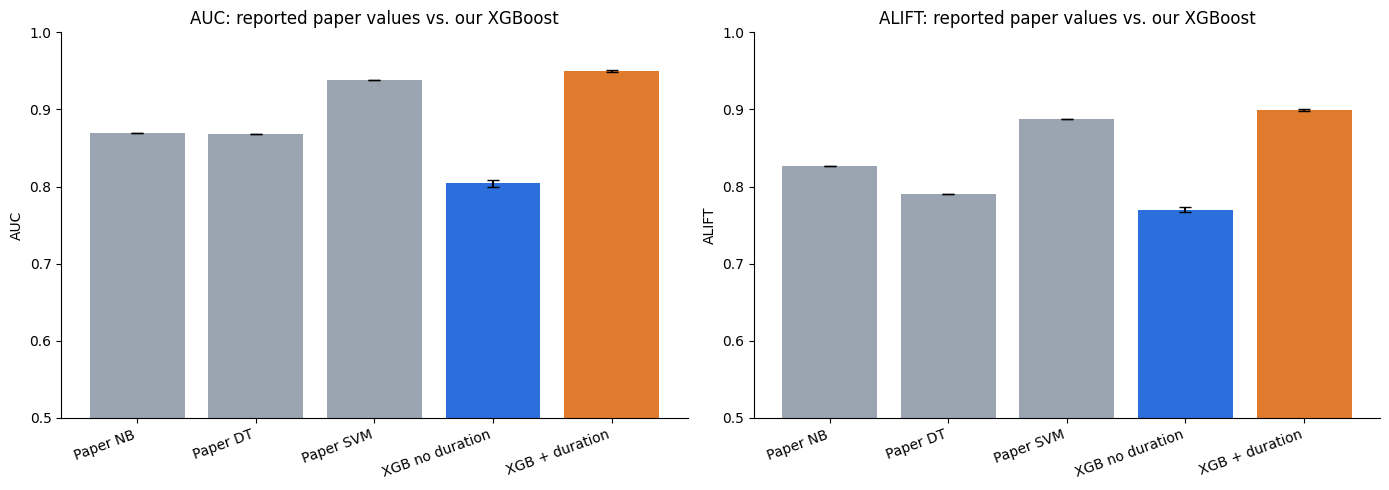

,AUC,ALIFT
Change from adding duration,0.1460,0.1290
No-duration XGBoost minus paper SVM,-0.1340,-0.1170
Duration XGBoost minus paper SVM,0.0120,0.0120


In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = ['Paper NB', 'Paper DT', 'Paper SVM', 'XGB no duration', 'XGB + duration']
order = list(paper_reported.index) + list(comparison_scenarios)
colors = ['#9aa5b1', '#9aa5b1', '#9aa5b1', '#2a6fdb', '#e07a2d']

for ax, metric in zip(axes, ['AUC', 'ALIFT']):
    values = comparison_table.loc[order, metric].to_numpy()
    error = np.zeros(len(order))
    error[-2:] = (
        duration_runs_df.groupby('scenario')[metric].std()
        .reindex(list(comparison_scenarios)).to_numpy()
    )
    ax.bar(np.arange(len(order)), values, color=colors, yerr=error, capsize=4)
    ax.set_xticks(np.arange(len(order)), labels, rotation=20, ha='right')
    ax.set_ylim(0.5, 1.0)
    ax.set_title(f'{metric}: reported paper values vs. our XGBoost')
    ax.set_ylabel(metric)

plt.tight_layout()
plt.show()

# Quantify the duration effect and compare each scenario with the paper's best reported model.
paper_best = paper_reported.loc['Paper — Gaussian SVM (reported)']
comparison_differences = pd.DataFrame({
    'Change from adding duration':
        our_means.loc['Our XGBoost — with duration']
        - our_means.loc['Our XGBoost — no duration'],
    'No-duration XGBoost minus paper SVM':
        our_means.loc['Our XGBoost — no duration'] - paper_best,
    'Duration XGBoost minus paper SVM':
        our_means.loc['Our XGBoost — with duration'] - paper_best,
}).T.round(3)
comparison_differences


### Interpretation and limitations

* The difference between the two XGBoost rows isolates the practical impact of adding final
  call duration while keeping the algorithm, data rows, split procedure, and hyperparameters
  fixed. The output table reports the exact mean change in AUC and ALIFT.
* The **no-duration** result is the appropriate estimate for the stated business objective:
  selecting clients before calls are placed.
* The **with-duration** result is expected to be much higher and helps explain why the paper
  reported strong performance. It must not be used to claim that the bank can know before a
  call whether that call will last 12 minutes.
* The paper values are not a controlled head-to-head algorithm test. The paper used a related
  but different dataset (45,211 contacts and a different feature set), while this notebook has
  41,176 cleaned contacts and includes economic variables. Consequently, differences reflect
  data and feature definitions as well as algorithms.
* The paper did not report XGBoost. Its three rows are historical reference values only; no
  paper algorithm is imported, tuned, or fitted in this notebook.


---
## Findings & Actionable Recommendations

### Business understanding

Only about one in nine historical contacts subscribed. The useful business output is therefore
a ranked calling list that concentrates likely subscribers near the top, not simply a high
overall accuracy score.

### Model conclusion

Average precision is the primary selection metric because the positive class is uncommon.
ROC-AUC is retained for general discrimination and comparison with the paper. The final model
table and the capacity analysis identify the cross-validation winner without selecting it on
the test set. Logistic Regression remains the interpretable benchmark; Random Forest and
XGBoost test whether nonlinear interactions produce a reproducible improvement.

### Actionable findings

1. **Prioritize the highest-scored segment.** Begin with the capacity levels in the lift table
   and choose a final cutoff using agent capacity, contact cost, expected deposit value, and the
   cost of missing a likely subscriber.
2. **Use a controlled pilot.** Compare a model-ranked group with the current targeting process
   and measure incremental subscriptions, deposit value, and cost per acquisition.
3. **Treat observed feature relationships as associations.** Previous campaign success,
   contact channel, month, client group, repeated contacts, and economic context may be useful
   predictors, but the notebook does not prove that changing them will cause subscriptions.
4. **Do not use final duration for pre-call targeting.** The duration-aware results explain the
   paper's high performance and support retrospective analysis. A real in-call model must be
   trained on timestamped elapsed-duration snapshots containing only information observable at
   each prediction time.
5. **Protect clients and monitor outcomes.** Respect consent and do-not-call rules, cap excessive
   contact attempts, and monitor precision, recall, AP, calibration, lift, stability, and group
   outcomes after deployment.

### Next steps

1. Pilot the pre-call XGBoost ranking against the bank's current targeting process.
2. Keep Random Forest as a close challenger during later-period validation.
3. Validate on later campaigns to test sensitivity to economic and seasonal change.
4. If an in-call model is desired, construct timestamped elapsed-call snapshots and validate it
   as a separate prediction system.
